In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing


In [3]:
data = fetch_california_housing(as_frame=True)

df = data.frame

print(df.head())

   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  MedHouseVal  
0    -122.23        4.526  
1    -122.22        3.585  
2    -122.24        3.521  
3    -122.25        3.413  
4    -122.25        3.422  


In [39]:
df.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


In [4]:
X = df.drop("MedHouseVal", axis=1)
y = df["MedHouseVal"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (20640, 8)
y shape: (20640,)


In [5]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print(X_train.shape, X_test.shape)

(16512, 8) (4128, 8)


#### If missing value exists then we can fill it with SimpleImputer

In [6]:
print("Missing values in X_train:")
print(X_train.isnull().sum())

print("Missing values in X_test:")
print(X_test.isnull().sum())

Missing values in X_train:
MedInc        0
HouseAge      0
AveRooms      0
AveBedrms     0
Population    0
AveOccup      0
Latitude      0
Longitude     0
dtype: int64
Missing values in X_test:
MedInc        0
HouseAge      0
AveRooms      0
AveBedrms     0
Population    0
AveOccup      0
Latitude      0
Longitude     0
dtype: int64


In [7]:
from sklearn.model_selection import train_test_split

X = df.drop("MedHouseVal", axis=1)
y = df["MedHouseVal"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

| Method                   | What it does                                                                       |
| ------------------------ | ---------------------------------------------------------------------------------- |
| `fit_transform(X_train)` | Learns the training-set mean and standard deviation, then scales the training data |
| `transform(X_test)`      | Scales the test data using the training-set statistics                             |


In [8]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [10]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train_scaled, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](8,)","[ 0.85, 0.12,-0.29,...,-0.04,-0.9 ,-0.87]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,2.072
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,8
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(8)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](8,)","[182.86,175.83,145. ,...,104.18, 36.96, 27.94]"


In [11]:
y_pred = model.predict(X_test_scaled)

print("Actual values:")
print(y_test[:5].values)

print("\nPredicted values:")
print(y_pred[:5])

Actual values:
[0.477   0.458   5.00001 2.186   2.78   ]

Predicted values:
[0.71912284 1.76401657 2.70965883 2.83892593 2.60465725]


| Metric | Meaning                                      | Better value          |
| ------ | -------------------------------------------- | --------------------- |
| MAE    | Average absolute prediction error            | Lower                 |
| MSE    | Average squared prediction error             | Lower                 |
| RMSE   | Error in the target's original units         | Lower                 |
| R²     | How much target variation the model explains | Generally closer to 1 |


In [12]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

MAE: 0.5332001304956565
MSE: 0.5558915986952444
RMSE: 0.7455813830127764
R2 Score: 0.5757877060324508


### **Heat-Map**
| Correlation | Meaning                             |
| ----------- | ----------------------------------- |
| `+1.00`     | Perfect positive linear correlation |
| `+0.75`     | Strong positive linear relationship |
| `0.00`      | No linear correlation               |
| `-0.75`     | Strong negative linear relationship |
| `-1.00`     | Perfect negative linear correlation |


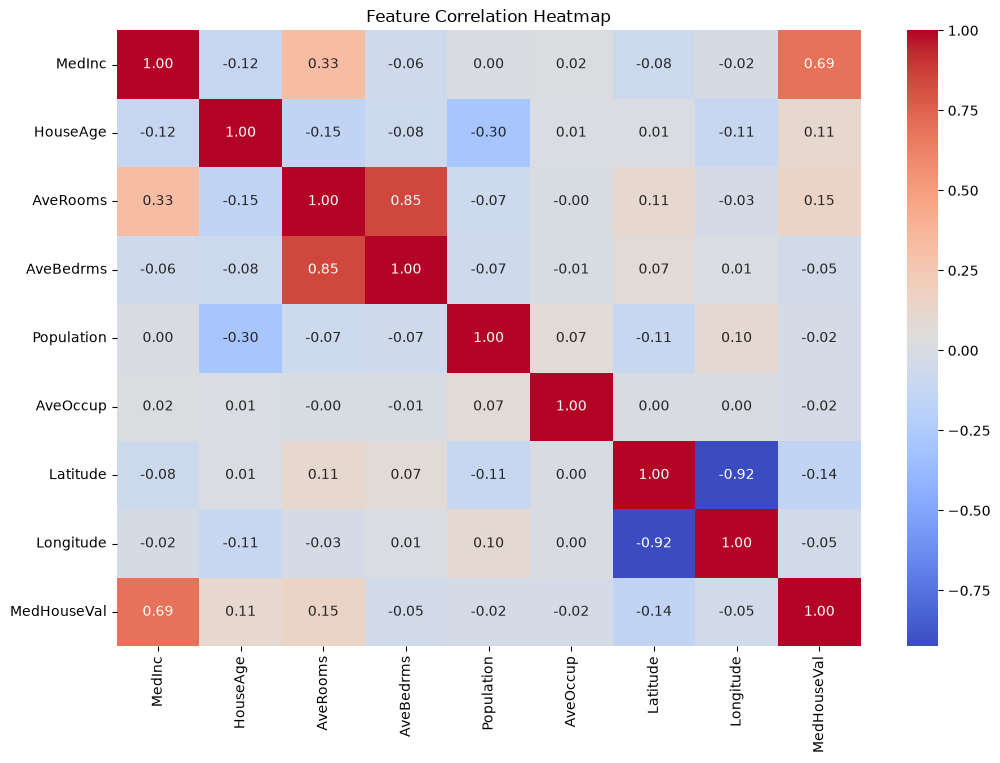

In [15]:
import seaborn as sns
import matplotlib.pyplot as plt

correlation = df.corr(numeric_only=True)

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Feature Correlation Heatmap")
plt.show()

In [13]:
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": model.coef_
})

feature_importance["Absolute_Coefficient"] = (
    feature_importance["Coefficient"].abs()
)

feature_importance = feature_importance.sort_values(
    by="Absolute_Coefficient",
    ascending=False
)

print(feature_importance)

      Feature  Coefficient  Absolute_Coefficient
6    Latitude    -0.896929              0.896929
7   Longitude    -0.869842              0.869842
0      MedInc     0.854383              0.854383
3   AveBedrms     0.339259              0.339259
2    AveRooms    -0.294410              0.294410
1    HouseAge     0.122546              0.122546
5    AveOccup    -0.040829              0.040829
4  Population    -0.002308              0.002308


If I randomly shuffle one feature's values, how much does my model's predictive performance deteriorate?

For Latitude, your importance is 1.207.

This means shuffling Latitude reduced the model's R² score by approximately 1.207 on average.

| Scoring                         | What it measures                                            | How to interpret importance                |
| ------------------------------- | ----------------------------------------------------------- | ------------------------------------------ |
| `"r2"`                          | How well predictions explain the variation in actual values | Decrease in R² after shuffling a feature   |
| `"neg_mean_absolute_error"`     | Average absolute prediction error                           | Increase in MAE after shuffling a feature  |
| `"neg_mean_squared_error"`      | Average squared prediction error                            | Increase in MSE after shuffling a feature  |
| `"neg_root_mean_squared_error"` | Root mean squared prediction error                          | Increase in RMSE after shuffling a feature |


In [16]:
from sklearn.inspection import permutation_importance

result = permutation_importance(
    model,
    X_test_scaled,
    y_test,
    n_repeats=5,
    random_state=42,
    scoring="r2"
)

importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": result.importances_mean
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print(importance_df)

      Feature  Importance
6    Latitude    1.207388
7   Longitude    1.147326
0      MedInc    1.039121
3   AveBedrms    0.258746
2    AveRooms    0.237336
1    HouseAge    0.022593
5    AveOccup    0.001057
4  Population    0.000002


In [18]:
residuals = y_test - y_pred

print(residuals.head())

20046   -0.242123
3024    -1.306017
15663    2.290351
20484   -0.652926
9814     0.175343
Name: MedHouseVal, dtype: float64


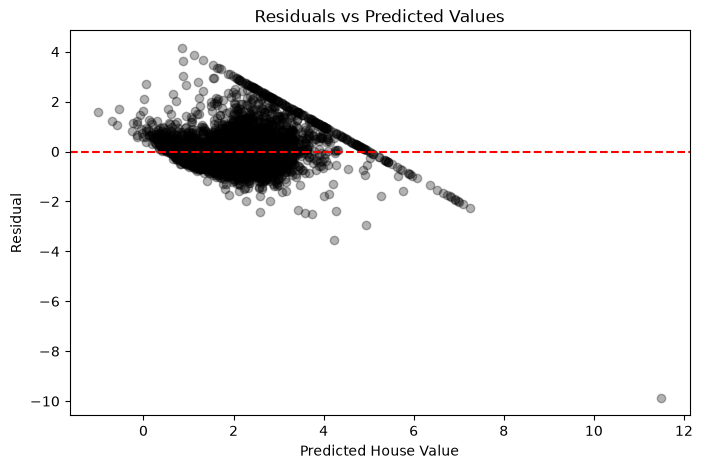

In [26]:
plt.figure(figsize=(8, 5))
plt.scatter(y_pred, residuals,c="black",alpha=0.3)
plt.axhline(y=0, color="red", linestyle="--")
plt.xlabel("Predicted House Value")
plt.ylabel("Residual")
plt.title("Residuals vs Predicted Values")
plt.show()

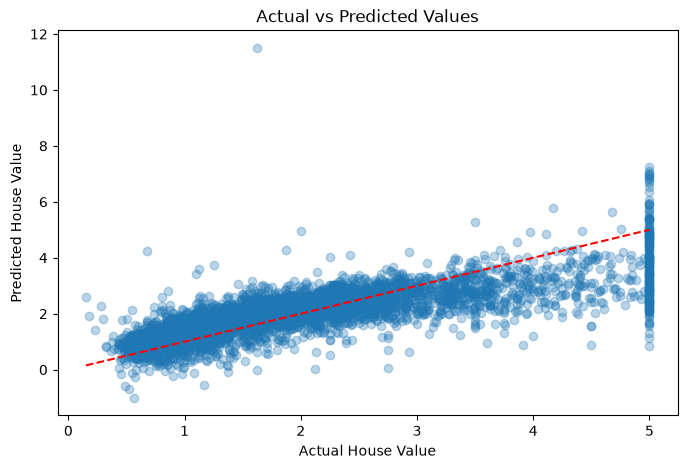

In [27]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred, alpha=0.3)

plt.plot([y_test.min(), y_test.max()],[y_test.min(), y_test.max()],"r--")

plt.xlabel("Actual House Value")
plt.ylabel("Predicted House Value")
plt.title("Actual vs Predicted Values")

plt.show()

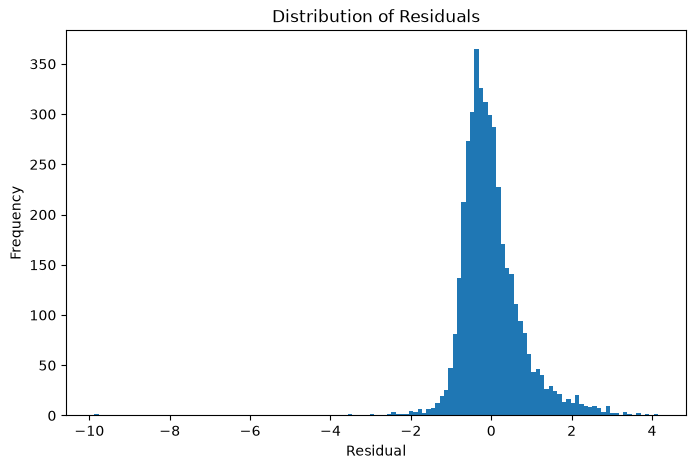

In [30]:
plt.figure(figsize=(8, 5))
plt.hist(residuals, bins="auto")
plt.xlabel("Residual")
plt.ylabel("Frequency")
plt.title("Distribution of Residuals")
plt.show()

In [31]:
print("Mean residual:", residuals.mean())
print("Mean absolute residual:", residuals.abs().mean())

Mean residual: 0.0034792979037499313
Mean absolute residual: 0.5332001304956565


## **Experimentations**

| Technique             | What we change                                             | Purpose                                          |
| --------------------- | ---------------------------------------------------------- | ------------------------------------------------ |
| Feature engineering   | Create or transform input features                         | Capture relationships the original features miss |
| Feature selection     | Remove irrelevant or redundant features                    | Reduce noise and simplify the model              |
| Regularization        | Adjust `alpha` in Ridge or Lasso                           | Control coefficient sizes and reduce overfitting |
| Hyperparameter tuning | Search for the best model settings                         | Find a better-performing configuration           |
| Model selection       | Compare Linear, Ridge, Lasso, and other regressors         | Find a model that fits the data better           |
| Data preprocessing    | Handle outliers, missing values, and scaling appropriately | Improve data quality and training stability      |


In [32]:
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

ridge_model = Ridge(alpha=1.0)

ridge_model.fit(X_train_scaled, y_train)

ridge_pred = ridge_model.predict(X_test_scaled)

print("MAE:", mean_absolute_error(y_test, ridge_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, ridge_pred)))
print("R2:", r2_score(y_test, ridge_pred))

MAE: 0.5331931195789734
RMSE: 0.7455567442814779
R2: 0.5758157428913684


| Feature                              | Ridge                       | Lasso                        |
| ------------------------------------ | --------------------------- | ---------------------------- |
| Regularization                       | L2                          | L1                           |
| Penalty                              | Sum of squared coefficients | Sum of absolute coefficients |
| Can reduce coefficients toward zero? | Yes                         | Yes                          |
| Can make coefficients exactly zero?  | Generally no                | Yes                          |
| Can perform feature selection?       | Not by zeroing coefficients | Yes                          |


In [33]:
from sklearn.linear_model import Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

lasso_model = Lasso(alpha=0.01, max_iter=10000)

lasso_model.fit(X_train_scaled, y_train)

lasso_pred = lasso_model.predict(X_test_scaled)

lasso_mae = mean_absolute_error(y_test, lasso_pred)
lasso_rmse = np.sqrt(mean_squared_error(y_test, lasso_pred))
lasso_r2 = r2_score(y_test, lasso_pred)

print("Lasso Regression")
print("MAE:", lasso_mae)
print("RMSE:", lasso_rmse)
print("R2 Score:", lasso_r2)

Lasso Regression
MAE: 0.5353261423609053
RMSE: 0.7404423656125414
R2 Score: 0.5816154300698727


In [34]:
lasso_coefficients = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": lasso_model.coef_
})

print(lasso_coefficients)

      Feature  Coefficient
0      MedInc     0.800957
1    HouseAge     0.127087
2    AveRooms    -0.162759
3   AveBedrms     0.206207
4  Population    -0.000000
5    AveOccup    -0.030602
6    Latitude    -0.790113
7   Longitude    -0.755674


In [35]:
zero_count = np.sum(lasso_model.coef_ == 0)

print("Total features:", len(lasso_model.coef_))
print("Zero coefficients:", zero_count)

Total features: 8
Zero coefficients: 1


In [ ]:
results = {
    "Linear Regression": [
        mean_absolute_error(y_test, y_pred),
        np.sqrt(mean_squared_error(y_test, y_pred)),
        r2_score(y_test, y_pred)
    ],
    "Ridge Regression": [
        mean_absolute_error(y_test, ridge_pred),
        np.sqrt(mean_squared_error(y_test, ridge_pred)),
        r2_score(y_test, ridge_pred)
    ],
    "Lasso Regression": [
        mean_absolute_error(y_test, lasso_pred),
        np.sqrt(mean_squared_error(y_test, lasso_pred)),
        r2_score(y_test, lasso_pred)
    ]
}

metrics_df = pd.DataFrame(
    results,
    index=["MAE", "RMSE", "R2"]
)

print(metrics_df)

      Linear Regression  Ridge Regression  Lasso Regression
MAE            0.533200          0.533193          0.535326
RMSE           0.745581          0.745557          0.740442
R2             0.575788          0.575816          0.581615


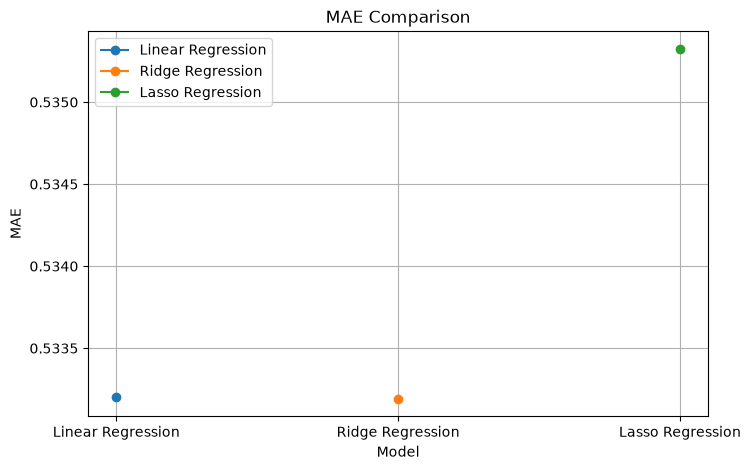

In [37]:
plt.figure(figsize=(8, 5))

for model_name in metrics_df.columns:
    plt.plot(
        model_name,
        metrics_df.loc["MAE", model_name],
        marker="o",
        label=model_name
    )

plt.title("MAE Comparison")
plt.xlabel("Model")
plt.ylabel("MAE")
plt.legend()
plt.grid(True)
plt.show()

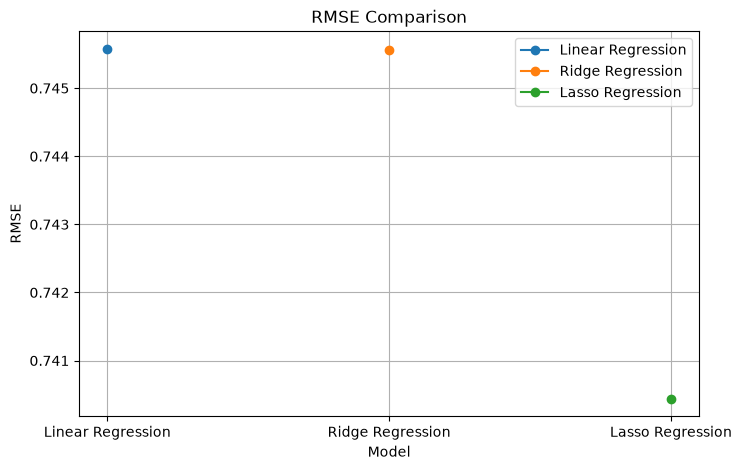

In [38]:
plt.figure(figsize=(8, 5))

for model_name in metrics_df.columns:
    plt.plot(
        model_name,
        metrics_df.loc["RMSE", model_name],
        marker="o",
        label=model_name
    )

plt.title("RMSE Comparison")
plt.xlabel("Model")
plt.ylabel("RMSE")
plt.legend()
plt.grid(True)
plt.show()